# Exercise 1

Create a model using K-Nearest Neigbors to perform classification using the personality dataset.

0 -'introvert'

1 - 'extrovert'

## A. Import libraries

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## B. Load and understand the dataset

Display the first 5 rows of the dataset using `.head()`

In [45]:
df = pd.read_excel("Datasets.xlsx")

In [46]:
df.head()

,Name,Posts/Share Frequently?,Active?,Replies to comments/messages?,Number of Friends/Followers,Personality
0,Karizza,0,1,1,890,1
1,Adrian,0,1,1,1201,0
2,Karl,0,1,1,500,1
3,Genesis,1,1,1,956,1
4,Charles,1,1,0,1900,0


Display the summary of all the features of the dataset using `.info()`

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Name                           5 non-null      object
 1   Posts/Share Frequently?        5 non-null      int64 
 2   Active?                        5 non-null      int64 
 3   Replies to comments/messages?  5 non-null      int64 
 4   Number of Friends/Followers    5 non-null      int64 
 5   Personality                    5 non-null      int64 
dtypes: int64(5), object(1)
memory usage: 372.0+ bytes


Display the total number of samples from each label using `.value_counts()`

In [48]:
df['Personality'].value_counts()

,count
Personality,
1,3
0,2


Use a histogram to display the number of followers for each samples
 - The x axis should be the number of followers/friends
 - The y axis should be the number of samples in the dataset

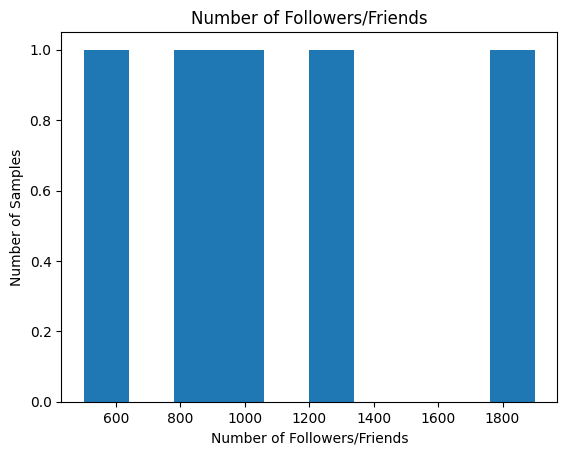

In [53]:
plt.hist(df['Number of Friends/Followers'])
plt.xlabel('Number of Followers/Friends')
plt.ylabel('Number of Samples')
plt.title('Number of Followers/Friends')
plt.show()

Remove the name column using `drop()` method

In [72]:
X = df.drop(columns=['Personality']).values

display(df.head())

,Posts/Share Frequently?,Active?,Replies to comments/messages?,Number of Friends/Followers,Personality
0,0,1,1,890,1
1,0,1,1,1201,0
2,0,1,1,500,1
3,1,1,1,956,1
4,1,1,0,1900,0


## C. Split the dataset into training and test set

Convert the features into an numpy array using `.values()` and store it in a variable "X"

In [83]:
X = df.drop(columns=['Personality']).values

Convert the labels into an numpy array using `.values()` and store it in a variable "y"

In [84]:
y = df['Personality'].values

Use `train_test_split()` to split the data.

- Declare a variable `X_train` that will hold the training data
- Declare a variable `X_test` that will hold the test data
- Declare a variable `y_train` that will hold the label of the training data
- Declare a variable `y_test` that will hold the label of the test data


In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


Display the dimensions of each variables using `.shape()`

In [86]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [87]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(4, 4)
(4,)
(1, 4)
(1,)


## D. Create the model

Use KNN as a classifier by using `KNeighborsClassifier()`

In [88]:
knn = KNeighborsClassifier(n_neighbors=3)

Train the model using the `.fit()`

In [89]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Test the model using the `.predict()`

In [80]:
y_pred = knn.predict(X_test)

print(y_pred)

[1]


## E. Evaluate the model

Create a confusion matrix

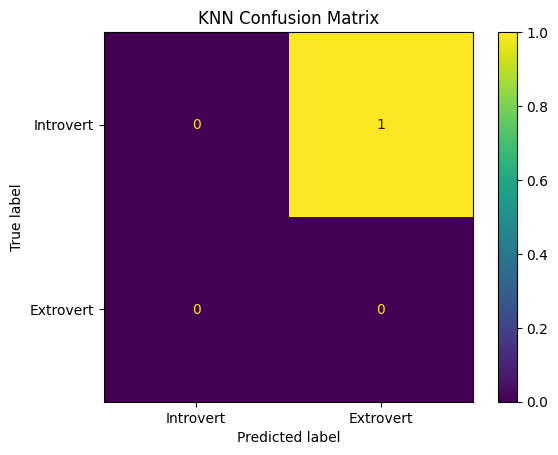

In [81]:
import numpy as np

# Get all unique labels from the original dataset (y) to ensure the confusion matrix has the correct dimensions
all_labels = np.unique(y)

cm = confusion_matrix(y_test, y_pred, labels=all_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Introvert', 'Extrovert']
)

disp.plot()
plt.title('KNN Confusion Matrix')
plt.show()

Display the accuracy

In [91]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.0


Display the precision

In [90]:
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
print("Precision:", precision)

Precision: 0.0


Display the recall

In [70]:
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
print("Recall:", recall)

Recall: 0.0


Display the f1-score

In [71]:
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print("F1-Score:", f1)

F1-Score: 0.0


## F. Predict your own personality

Enter your own features and use the model to generate a prediction using `.predict()`

In [93]:
my_features = [[
    5,    # Post/Share Frequently
    1,    # Active
    1,    # Replies to comments/messages?
    500   # Followers
]]

prediction = knn.predict(my_features)

if prediction[0] == 0:
    print("Predicted Personality: Introvert")
else:
    print("Predicted Personality: Extrovert")

Predicted Personality: Extrovert
